# Projeto 5 — Transformers: classificação de emoções em textos

**UC de Redes Neurais**

O objetivo é classificar emoções em textos em inglês com o dataset [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion). Utilizamos DistilBERT com fine-tuning em PyTorch e Hugging Face Transformers.

O notebook contempla a preparação do ambiente, a exploração dos dados, a tokenização, o carregamento do DistilBERT e os experimentos com encoder congelado, baseline de cinco épocas e otimização com Optuna. As classes são **sadness, joy, love, anger, fear e surprise**. O treinamento deve ser executado manualmente; o teste permanece reservado para a comparação final.

No **Google Colab**, execute as células em ordem. É necessário acesso à internet para instalar as dependências e baixar os dados. Esta etapa pode ser executada em CPU.


## Instalação das bibliotecas

O comando instala as dependências que ainda não estiverem disponíveis. PyTorch e Transformers também preparam o ambiente para as etapas futuras.


In [ ]:
%pip install -q torch transformers datasets pandas matplotlib numpy accelerate scikit-learn optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\davis\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Importações e reprodutibilidade

Fixamos a semente em **42** para Python, NumPy e PyTorch. Isso ajuda na reprodutibilidade; resultados exatos podem variar entre versões e dispositivos.


In [35]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import display

SEMENTE = 42

random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)

# Configura também as sementes e o cuDNN, caso haja GPU.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMENTE)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Semente configurada: {SEMENTE}")


Semente configurada: 42


## Carregamento do dataset

Usamos a configuração **`split`**, que fornece as divisões originais `train`, `validation` e `test`. Não criamos novas divisões nem alteramos os exemplos.

Cada registro contém um texto (`text`) e um rótulo numérico (`label`). Obtemos os nomes das emoções dos metadados do dataset.


In [36]:
# O segundo argumento seleciona a configuração do dataset.
dataset = load_dataset("dair-ai/emotion", "split")

divisoes = {
    "train": "Treinamento",
    "validation": "Validação",
    "test": "Teste",
}

nomes_classes = dataset["train"].features["label"].names
tabela_classes = pd.DataFrame({
    "Rótulo": range(len(nomes_classes)),
    "Emoção": nomes_classes,
})
display(tabela_classes)

# Cópias em DataFrames facilitam a exploração sem alterar o dataset.
dados = {divisao: dataset[divisao].to_pandas() for divisao in divisoes}


,Rótulo,Emoção
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


## Quantidade de exemplos e visualização dos textos

A tabela mostra o tamanho de cada divisão original. Em seguida, exibimos um exemplo de treinamento por emoção, mantendo os textos em inglês.


In [37]:
quantidades = pd.DataFrame({
    "Divisão": list(divisoes.values()),
    "Exemplos": [len(dataset[divisao]) for divisao in divisoes],
})
display(quantidades)
print(f"Total de exemplos: {quantidades['Exemplos'].sum():,}")

# Seleciona exemplos apenas para exibição; o conjunto permanece completo.
exemplos = (
    dados["train"]
    .groupby("label", sort=True)
    .head(1)
    .sort_values("label")
    .copy()
)
exemplos["Emoção"] = exemplos["label"].map(dict(enumerate(nomes_classes)))
exemplos = exemplos.rename(columns={"text": "Texto", "label": "Rótulo"})

with pd.option_context("display.max_colwidth", None):
    display(exemplos[["Texto", "Rótulo", "Emoção"]].reset_index(drop=True))


,Divisão,Exemplos
0,Treinamento,16000
1,Validação,2000
2,Teste,2000


Total de exemplos: 20,000


,Texto,Rótulo,Emoção
0,i didnt feel humiliated,0,sadness
1,i have been with petronas for years i feel that petronas has performed well and made a huge profit,1,joy
2,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,2,love
3,im grabbing a minute to post i feel greedy wrong,3,anger
4,i feel as confused about life as a teenager or as jaded as a year old man,4,fear
5,ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny,5,surprise


## Distribuição das seis classes

As tabelas apresentam a quantidade e o percentual de cada emoção por divisão. O gráfico compara as quantidades. Essa análise permite identificar possíveis desequilíbrios antes do futuro treinamento.


Quantidade de exemplos por emoção:


,Treinamento,Validação,Teste
Emoção,,,
sadness,4666,550,581
joy,5362,704,695
love,1304,178,159
anger,2159,275,275
fear,1937,212,224
surprise,572,81,66


Percentual por emoção dentro de cada divisão (%):


,Treinamento,Validação,Teste
Emoção,,,
sadness,29.16,27.50,29.05
joy,33.51,35.20,34.75
love,8.15,8.90,7.95
anger,13.49,13.75,13.75
fear,12.11,10.60,11.20
surprise,3.58,4.05,3.30


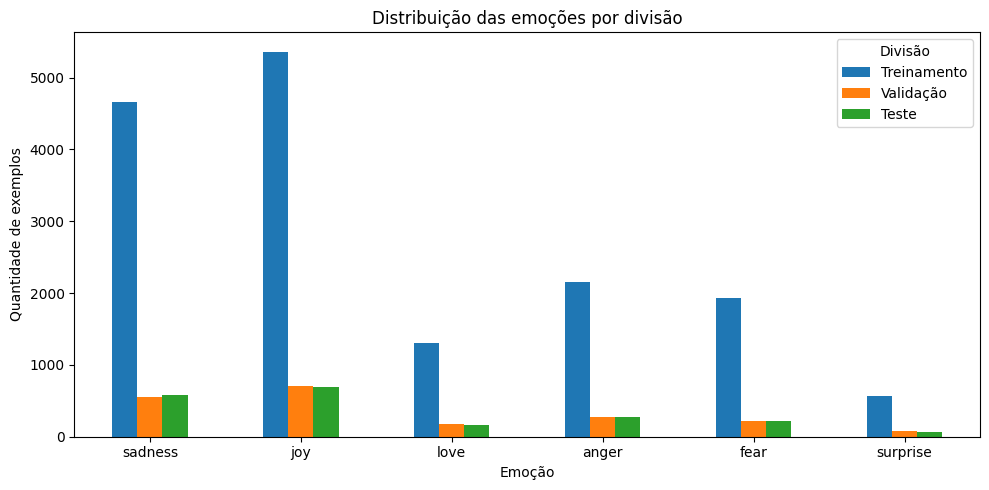

In [38]:
# Reindexar mantém todas as seis classes, mesmo se alguma tiver contagem zero.
contagens = pd.DataFrame({
    nome: dados[divisao]["label"].value_counts().reindex(
        range(len(nomes_classes)), fill_value=0
    )
    for divisao, nome in divisoes.items()
})
contagens.index = pd.Index(nomes_classes, name="Emoção")

percentuais = contagens.div(contagens.sum(axis=0), axis=1).mul(100)

print("Quantidade de exemplos por emoção:")
display(contagens)
print("Percentual por emoção dentro de cada divisão (%):")
display(percentuais.round(2))

ax = contagens.plot.bar(figsize=(10, 5), rot=0)
ax.set_title("Distribuição das emoções por divisão")
ax.set_xlabel("Emoção")
ax.set_ylabel("Quantidade de exemplos")
ax.legend(title="Divisão")
plt.tight_layout()
plt.show()


## Verificação de textos vazios e valores ausentes

Contamos valores ausentes nas colunas `text` e `label` em cada divisão. Também verificamos textos vazios, incluindo aqueles formados apenas por espaços. Valores ausentes são contados separadamente dos textos vazios.

Esta etapa apenas inspeciona os dados; nenhum exemplo será removido, preenchido ou modificado.


In [39]:
verificacoes = []

for divisao, nome in divisoes.items():
    df = dados[divisao]

    # O tipo string preserva ausentes; strip permite detectar só espaços.
    textos_vazios = df["text"].astype("string").str.strip().eq("").fillna(False)

    verificacoes.append({
        "Divisão": nome,
        "Textos ausentes": int(df["text"].isna().sum()),
        "Rótulos ausentes": int(df["label"].isna().sum()),
        "Textos vazios ou só espaços": int(textos_vazios.sum()),
    })

qualidade = pd.DataFrame(verificacoes).set_index("Divisão")
display(qualidade)

if qualidade.to_numpy().sum() == 0:
    print("Não foram encontrados textos vazios nem valores ausentes em text e label.")
else:
    print("Foram encontrados problemas. Revise a tabela antes de avançar no projeto.")


,Textos ausentes,Rótulos ausentes,Textos vazios ou só espaços
Divisão,,,
Treinamento,0,0,0
Validação,0,0,0
Teste,0,0,0


Não foram encontrados textos vazios nem valores ausentes em text e label.


## Tokenização dos textos

Usamos `AutoTokenizer` com o checkpoint **distilbert-base-uncased**. A tokenização mantém a ordem dos exemplos e os rótulos originais, limita as sequências a **128 tokens** (incluindo tokens especiais) e não adiciona padding nesta etapa.

O `DataCollatorWithPadding` fará o **padding dinâmico** até o maior comprimento de cada lote, produzindo tensores PyTorch. A coluna de texto é removida apenas da cópia tokenizada; o dataset original permanece disponível.

A constante `NOME_MODELO` define o checkpoint comum ao tokenizer e ao modelo e deve ser reutilizada posteriormente no baseline e no Optuna. Referência: [classificação de textos com Hugging Face](https://huggingface.co/docs/transformers/tasks/sequence_classification).


In [40]:
from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    AutoModelForSequenceClassification,
)

NOME_MODELO = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(NOME_MODELO)


def tokenizar_textos(exemplos):
    return tokenizer(
        exemplos["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )


# DatasetDict.map aplica a função às três divisões, sem criar novas divisões.
dataset_tokenizado = dataset.map(
    tokenizar_textos,
    batched=True,
    remove_columns=["text"],
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)


### Exemplo tokenizado e verificação das divisões

Mostramos o texto original, os tokens, seus identificadores e a máscara de atenção. Verificamos a quantidade e a ordem dos rótulos em cada divisão, além dos comprimentos das sequências e máscaras.

Um pequeno lote permite conferir o padding e o formato dos tensores, sem passar dados pelo modelo. O collator renomeia `label` para `labels`, como esperado pelo modelo, preservando os valores.


In [41]:
exemplo_original = dataset["train"][0]
exemplo_tokenizado = dataset_tokenizado["train"][0]

print("Texto original:", exemplo_original["text"])
print("Emoção:", nomes_classes[exemplo_original["label"]])
print("Tokens:", tokenizer.convert_ids_to_tokens(exemplo_tokenizado["input_ids"]))
print("input_ids:", exemplo_tokenizado["input_ids"])
print("attention_mask:", exemplo_tokenizado["attention_mask"])
print("Rótulo preservado:", exemplo_tokenizado["label"])

resumo_tokenizacao = []

assert set(dataset_tokenizado) == set(divisoes)

for divisao, nome in divisoes.items():
    original = dataset[divisao]
    tokenizado = dataset_tokenizado[divisao]

    assert len(tokenizado) == len(original), f"Quantidade alterada em {nome}"
    assert list(tokenizado["label"]) == list(original["label"]), (
        f"Rótulos ou ordem alterados em {nome}"
    )
    assert {"input_ids", "attention_mask", "label"}.issubset(tokenizado.column_names)

    comprimentos = [len(ids) for ids in tokenizado["input_ids"]]
    assert all(0 < tamanho <= MAX_LENGTH for tamanho in comprimentos)
    assert all(
        len(ids) == len(mascara) and all(valor == 1 for valor in mascara)
        for ids, mascara in zip(tokenizado["input_ids"], tokenizado["attention_mask"])
    ), f"Máscara inconsistente ou padding antecipado em {nome}"

    resumo_tokenizacao.append({
        "Divisão": nome,
        "Exemplos": len(tokenizado),
        "Menor sequência": min(comprimentos),
        "Maior sequência": max(comprimentos),
        "Rótulos preservados": True,
    })

display(pd.DataFrame(resumo_tokenizacao))

# O padding é aplicado somente ao formar o lote.
amostras = [dataset_tokenizado["train"][i] for i in range(3)]
lote_exemplo = data_collator(amostras)
assert lote_exemplo["input_ids"].shape[1] == max(
    len(amostra["input_ids"]) for amostra in amostras
)
assert lote_exemplo["labels"].tolist() == [amostra["label"] for amostra in amostras]
print("Formato dos tensores no lote:")
for campo, tensor in lote_exemplo.items():
    print(f"{campo}: {tuple(tensor.shape)} — {tensor.dtype}")

print("As três divisões foram tokenizadas e verificadas.")


Texto original: i didnt feel humiliated
Emoção: sadness
Tokens: ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]']
input_ids: [101, 1045, 2134, 2102, 2514, 26608, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1]
Rótulo preservado: 0


,Divisão,Exemplos,Menor sequência,Maior sequência,Rótulos preservados
0,Treinamento,16000,4,87,True
1,Validação,2000,4,69,True
2,Teste,2000,5,66,True


Formato dos tensores no lote:
input_ids: (3, 23) — torch.int64
token_type_ids: (3, 23) — torch.int64
attention_mask: (3, 23) — torch.int64
labels: (3,) — torch.int64
As três divisões foram tokenizadas e verificadas.


## Carregamento do DistilBERT

Utilizamos um **Transformer pré-treinado** para representar os textos, com uma **cabeça de classificação de seis saídas**, uma por emoção. Essa cabeça é inicializada para a nossa tarefa e precisará ser treinada posteriormente; o aviso sobre pesos recém-inicializados é esperado.

Os mapeamentos `id2label` e `label2id` seguem a ordem original dos metadados do dataset. O modelo será colocado na GPU se CUDA estiver disponível, ou na CPU. Todos os parâmetros permanecem treináveis para o futuro fine-tuning.

Referência: [checkpoint DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased).


In [42]:
# Confere a ordem original das seis emoções antes de configurar o modelo.
assert nomes_classes == ["sadness", "joy", "love", "anger", "fear", "surprise"]

id2label = dict(enumerate(nomes_classes))
label2id = {emocao: indice for indice, emocao in id2label.items()}

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Torna reproduzível também a inicialização da nova cabeça ao reexecutar a célula.
torch.manual_seed(SEMENTE)
modelo = AutoModelForSequenceClassification.from_pretrained(
    NOME_MODELO,
    num_labels=6,
    id2label=id2label,
    label2id=label2id,
)
modelo = modelo.to(dispositivo)

assert modelo.config.num_labels == 6
assert modelo.config.id2label == id2label
assert modelo.config.label2id == label2id

parametros_totais = sum(parametro.numel() for parametro in modelo.parameters())
parametros_treinaveis = sum(
    parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
)

print(f"Checkpoint: {NOME_MODELO}")
print(f"Arquitetura: {modelo.__class__.__name__}")
print(f"Dispositivo: {next(modelo.parameters()).device}")
print(f"Camadas Transformer: {modelo.config.n_layers}")
print(f"Cabeças de atenção por camada: {modelo.config.n_heads}")
print(f"Dimensão das representações: {modelo.config.dim}")
print(f"Cabeça de classificação: {modelo.classifier}")
print(f"Parâmetros totais: {parametros_totais:,}")
print(f"Parâmetros treináveis: {parametros_treinaveis:,}")
display(pd.DataFrame({
    "Rótulo": list(id2label.keys()),
    "Emoção": list(id2label.values()),
}))


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: distilbert-base-uncased
Arquitetura: DistilBertForSequenceClassification
Dispositivo: cuda:0
Camadas Transformer: 6
Cabeças de atenção por camada: 12
Dimensão das representações: 768
Cabeça de classificação: Linear(in_features=768, out_features=6, bias=True)
Parâmetros totais: 66,958,086
Parâmetros treináveis: 66,958,086


,Rótulo,Emoção
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


## Protocolo dos três experimentos

Comparamos **encoder congelado**, **fine-tuning completo com parâmetros fixos** e **fine-tuning completo otimizado pelo Optuna**. Todos usam o mesmo checkpoint original, tokenização, divisões e seed 42. A escolha dos checkpoints e hiperparâmetros utiliza somente validação.

O baseline anterior de três épocas é preservado em `results/baseline_3epocas/` antes de qualquer nova gravação. O novo baseline e o encoder congelado usam até cinco épocas, AdamW, learning rate 2e-5, batch size 16, weight decay 0.01 e scheduler constante sem warmup. Apenas o Optuna utiliza early stopping, com paciência de duas avaliações.

As funções abaixo centralizam treinamento, avaliação e exportação para evitar versões diferentes do mesmo procedimento. Referências: [Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), [early stopping](https://huggingface.co/docs/transformers/main_classes/callback).


In [43]:
import gc
import inspect
import json
import math
import shutil
import tempfile
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import optuna
from optuna.trial import TrialState
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support,
)
from transformers import (
    Trainer, TrainingArguments, TrainerCallback, EarlyStoppingCallback, set_seed,
)

RAIZ_RESULTADOS = Path("results")
RAIZ_RESULTADOS.mkdir(exist_ok=True)
ROTULOS = list(range(len(nomes_classes)))
HIPERPARAMETROS_FIXOS = {
    "modelo": NOME_MODELO, "learning_rate": 2e-5, "batch_size": 16,
    "epocas": 5, "weight_decay": 0.01, "max_length": MAX_LENGTH,
    "seed": 42, "otimizador": "AdamW", "scheduler": "constant",
    "warmup_ratio": 0.0,
}
assert NOME_MODELO == "distilbert-base-uncased" and MAX_LENGTH == 128
assert SEMENTE == 42

# Libera o modelo demonstrativo: cada experimento carrega pesos originais novos.
if "modelo" in globals():
    del modelo
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


def salvar_json(caminho, conteudo):
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    caminho.write_text(
        json.dumps(conteudo, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


def preservar_resultados(pasta):
    pasta = Path(pasta)
    arquivo_hp = pasta / "hiperparametros.json"
    if not arquivo_hp.exists():
        return
    hp_anterior = json.loads(arquivo_hp.read_text(encoding="utf-8"))
    if pasta.name == "baseline" and hp_anterior.get("epocas") == 3:
        destino = RAIZ_RESULTADOS / "baseline_3epocas"
        if destino.exists():
            # Não sobrescreve um arquivo histórico já preservado.
            return
    else:
        identificador = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        destino = RAIZ_RESULTADOS / "historico" / f"{pasta.name}_{identificador}"
    shutil.copytree(pasta, destino)
    print("Experimento anterior preservado em:", destino)


def criar_modelo_experimento(congelado=False):
    set_seed(SEMENTE)
    novo_modelo = AutoModelForSequenceClassification.from_pretrained(
        NOME_MODELO, num_labels=len(nomes_classes),
        id2label=id2label, label2id=label2id,
    )
    if congelado:
        # Inclui embeddings e todas as camadas Transformer no congelamento.
        for parametro in novo_modelo.distilbert.parameters():
            parametro.requires_grad = False
        assert not any(p.requires_grad for p in novo_modelo.distilbert.parameters())
        assert all(p.requires_grad for p in novo_modelo.pre_classifier.parameters())
        assert all(p.requires_grad for p in novo_modelo.classifier.parameters())
    return novo_modelo


def metricas_durante_treino(predicao):
    logits = predicao.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    previstas = np.argmax(logits, axis=-1)
    return {
        "accuracy": float(accuracy_score(predicao.label_ids, previstas)),
        "f1_macro": float(f1_score(
            predicao.label_ids, previstas, labels=ROTULOS,
            average="macro", zero_division=0,
        )),
    }


def criar_trainer(modelo_atual, hp, pasta_checkpoint, callbacks=None):
    # Calcula warmup_steps: também funciona em versões sem warmup_ratio.
    passos_epoca = math.ceil(len(dataset_tokenizado["train"]) / hp["batch_size"])
    warmup_steps = int(passos_epoca * hp["epocas"] * hp.get("warmup_ratio", 0.0))
    parametros = {
        "output_dir": str(pasta_checkpoint),
        "learning_rate": hp["learning_rate"],
        "per_device_train_batch_size": hp["batch_size"],
        "per_device_eval_batch_size": hp["batch_size"],
        "num_train_epochs": hp["epocas"],
        "weight_decay": hp["weight_decay"],
        "optim": "adamw_torch", "lr_scheduler_type": hp["scheduler"],
        "warmup_steps": warmup_steps, "gradient_accumulation_steps": 1,
        "logging_strategy": "epoch", "save_strategy": "epoch",
        "save_total_limit": 1, "load_best_model_at_end": True,
        "metric_for_best_model": "f1_macro", "greater_is_better": True,
        "seed": SEMENTE, "data_seed": SEMENTE, "full_determinism": True,
        "dataloader_num_workers": 0, "fp16": False, "bf16": False,
        "report_to": "none",
    }
    assinatura = inspect.signature(TrainingArguments.__init__).parameters
    estrategia = "eval_strategy" if "eval_strategy" in assinatura else "evaluation_strategy"
    parametros[estrategia] = "epoch"
    argumentos = TrainingArguments(**parametros)
    configuracao = {
        "model": modelo_atual, "args": argumentos,
        "train_dataset": dataset_tokenizado["train"],
        "eval_dataset": dataset_tokenizado["validation"],
        "data_collator": data_collator,
        "compute_metrics": metricas_durante_treino,
        "callbacks": callbacks or [],
    }
    assinatura_trainer = inspect.signature(Trainer.__init__).parameters
    processador = "processing_class" if "processing_class" in assinatura_trainer else "tokenizer"
    configuracao[processador] = tokenizer
    return Trainer(**configuracao)


## Funções comuns de avaliação e gráficos

Cada avaliação exporta Accuracy, Precision, Recall e F1 (macro e weighted), relatório por emoção e matriz de confusão. Os históricos e gráficos mostram loss de treinamento, loss de validação e Macro F1 por época. Nenhuma métrica é criada sem previsões reais.

A função recebe explicitamente a divisão avaliada. Durante os treinamentos e a busca, as chamadas usam exclusivamente `validation`.


In [44]:
def avaliar_e_salvar(trainer, divisao, pasta, graficos=True):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    predicao = trainer.predict(dataset_tokenizado[divisao], metric_key_prefix=divisao)
    logits = predicao.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    reais = predicao.label_ids
    previstas = np.argmax(logits, axis=-1)
    metricas = {
        "divisao": divisao,
        "loss": float(predicao.metrics[f"{divisao}_loss"]),
        "accuracy": float(accuracy_score(reais, previstas)),
    }
    for media in ("macro", "weighted"):
        precisao, recall, f1, _ = precision_recall_fscore_support(
            reais, previstas, labels=ROTULOS, average=media, zero_division=0,
        )
        metricas.update({
            f"precision_{media}": float(precisao),
            f"recall_{media}": float(recall), f"f1_{media}": float(f1),
        })
    salvar_json(pasta / ("metricas_validacao.json" if divisao == "validation" else "metricas_teste.json"), metricas)
    relatorio = classification_report(
        reais, previstas, labels=ROTULOS, target_names=nomes_classes,
        zero_division=0, output_dict=True,
    )
    relatorio_texto = classification_report(
        reais, previstas, labels=ROTULOS, target_names=nomes_classes,
        zero_division=0, digits=4,
    )
    salvar_json(pasta / "relatorio_classificacao.json", relatorio)
    (pasta / "relatorio_classificacao.txt").write_text(relatorio_texto, encoding="utf-8")
    pd.DataFrame(relatorio).T.to_csv(pasta / "relatorio_classificacao.csv")
    matriz = confusion_matrix(reais, previstas, labels=ROTULOS)
    pd.DataFrame(matriz, index=nomes_classes, columns=nomes_classes).to_csv(
        pasta / "matriz_confusao.csv", index_label="Emoção real",
    )
    if graficos:
        print(relatorio_texto)
        display(pd.DataFrame([metricas]))
        fig, ax = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay(matriz, display_labels=nomes_classes).plot(
            ax=ax, cmap="Blues", values_format="d", colorbar=False,
        )
        ax.set(title=f"Matriz de confusão — {divisao}",
               xlabel="Emoção prevista", ylabel="Emoção real")
        fig.tight_layout()
        fig.savefig(pasta / "matriz_confusao.png", dpi=150)
        plt.show()
        plt.close(fig)
    return metricas


def salvar_historico(historico, pasta, graficos=True):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    salvar_json(pasta / "historico_treinamento.json", historico)
    df = pd.DataFrame(historico)
    df.to_csv(pasta / "historico_treinamento.csv", index=False)
    if "eval_f1_macro" not in df:
        return
    validacao = df.loc[df["eval_f1_macro"].notna(),
                       ["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
    treino = df.loc[df["loss"].notna(), ["epoch", "loss"]]
    epocas = treino.merge(validacao, on="epoch", how="outer")
    epocas.to_csv(pasta / "historico_epocas.csv", index=False)
    if not graficos:
        return
    display(epocas)
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    eixos[0].plot(treino["epoch"], treino["loss"], "o-", label="Treinamento")
    eixos[0].plot(validacao["epoch"], validacao["eval_loss"], "o-", label="Validação")
    eixos[0].set(title="Evolução da loss", xlabel="Época", ylabel="Loss")
    eixos[0].legend()
    eixos[1].plot(validacao["epoch"], validacao["eval_f1_macro"], "o-")
    eixos[1].set(title="Macro F1 na validação", xlabel="Época", ylabel="Macro F1", ylim=(0, 1))
    fig.tight_layout()
    fig.savefig(pasta / "evolucao_treinamento.png", dpi=150)
    for eixo, nome in zip(eixos, ("evolucao_loss.png", "evolucao_macro_f1.png")):
        extensao = eixo.get_tightbbox(fig.canvas.get_renderer()).transformed(
            fig.dpi_scale_trans.inverted()
        )
        fig.savefig(pasta / nome, dpi=150, bbox_inches=extensao.expanded(1.05, 1.1))
    plt.show()
    plt.close(fig)


## Função comum de treinamento

Cada execução inicia um DistilBERT novo e seleciona o checkpoint pelo maior Macro F1 na validação. No experimento congelado, os parâmetros do encoder não recebem atualizações; as camadas `pre_classifier`, dropout da cabeça e `classifier` continuam compondo a cabeça treinável.

O tempo inclui treino, validações e checkpoints. Após preservar os artefatos, a pasta temporária de checkpoints é removida e as referências ao modelo são liberadas da GPU. Uma nova execução preserva os resultados anteriores antes de substituí-los.


In [45]:
def treinar_experimento(nome, hp, congelado=False, trial=None, early_stopping=False):
    pasta = (
        RAIZ_RESULTADOS / "optuna" / "trials" / f"trial_{trial.number:03d}"
        if trial is not None else RAIZ_RESULTADOS / nome
    )
    if trial is None:
        preservar_resultados(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    hp = {**hp, "encoder_congelado": congelado,
          "early_stopping_patience": 2 if early_stopping else None}
    salvar_json(pasta / "hiperparametros.json", hp)
    modelo_atual = None
    trainer = None
    inicio = perf_counter()
    historico = []
    estado = "FAIL"
    try:
        modelo_atual = criar_modelo_experimento(congelado)
        contagem = {
            "totais": sum(p.numel() for p in modelo_atual.parameters()),
            "treinaveis": sum(p.numel() for p in modelo_atual.parameters() if p.requires_grad),
        }
        salvar_json(pasta / "parametros_modelo.json", contagem)
        print(nome, contagem)
        callbacks = []
        if early_stopping:
            callbacks.append(EarlyStoppingCallback(early_stopping_patience=2))
        if trial is not None:
            callbacks.append(RelatarTrialCallback(trial, pasta))
        with tempfile.TemporaryDirectory(prefix="checkpoints_", dir=pasta) as temporaria:
            trainer = criar_trainer(modelo_atual, hp, temporaria, callbacks)
            (pasta / "argumentos_treinamento.json").write_text(
                trainer.args.to_json_string(), encoding="utf-8",
            )
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            inicio = perf_counter()
            trainer.train()
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            segundos = perf_counter() - inicio
            historico = list(trainer.state.log_history)
            avaliacoes = [r for r in historico if "eval_f1_macro" in r]
            melhor = max(avaliacoes, key=lambda r: r["eval_f1_macro"])
            selecao = {
                "criterio": "Macro F1 na validação",
                "f1_macro": float(melhor["eval_f1_macro"]),
                "epoca_selecionada": float(melhor["epoch"]),
                "epocas_executadas": float(trainer.state.epoch),
            }
            salvar_json(pasta / "selecao_melhor_modelo.json", selecao)
            salvar_json(pasta / "tempo_treinamento.json", {"segundos": segundos})
            salvar_historico(historico, pasta, graficos=trial is None)
            metricas = avaliar_e_salvar(trainer, "validation", pasta, graficos=trial is None)
            if trial is None:
                destino_modelo = pasta / "melhor_modelo"
                trainer.save_model(str(destino_modelo))
                tokenizer.save_pretrained(str(destino_modelo))
            else:
                trial.set_user_attr("epoca_selecionada", selecao["epoca_selecionada"])
                trial.set_user_attr("metricas_validacao", metricas)
            salvar_json(pasta / "ambiente.json", {
                "bibliotecas": {n: version(n) for n in (
                    "torch", "transformers", "datasets", "accelerate", "optuna", "scikit-learn",
                )},
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            })
            estado = "COMPLETE"
            return {**selecao, "metricas": metricas, "tempo_segundos": segundos}
    except optuna.TrialPruned:
        estado = "PRUNED"
        raise
    finally:
        duracao_total = perf_counter() - inicio
        # Também preserva o histórico de trials podados ou que falharam.
        if trainer is not None and estado != "COMPLETE":
            salvar_historico(list(trainer.state.log_history), pasta, graficos=False)
        salvar_json(pasta / "estado_execucao.json", {
            "estado": estado, "duracao_total_segundos": duracao_total,
        })
        if trial is not None:
            trial.set_user_attr("duracao_total_segundos", duracao_total)
        # Accelerate também pode manter referências; o Trainer sai do escopo aqui.
        if trainer is not None:
            trainer.accelerator.free_memory()
        trainer = None
        modelo_atual = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


## Baseline com fine-tuning completo e cinco épocas

O baseline usa **cinco épocas**, mantendo os demais hiperparâmetros. Os resultados anteriores são preservados antes das novas gravações em `results/baseline/`.

Execute a célula abaixo para treinar. O Trainer usa GPU CUDA quando disponível e CPU nos demais casos. Para executar o experimento completo no Colab, selecione um ambiente com GPU antes de executar todas as células.


Experimento anterior preservado em: results\historico\baseline_20261116_143629_104179


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline {'totais': 66958086, 'treinaveis': 66958086}


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.468403,0.205028,0.928500,0.901451
2,0.154136,0.171134,0.934500,0.908746
3,0.122701,0.180259,0.938500,0.913975
4,0.098888,0.195999,0.938500,0.915268
5,0.076921,0.288435,0.928500,0.902206


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.468403,0.205028,0.9285,0.901451
1,2.0,0.154136,0.171134,0.9345,0.908746
2,3.0,0.122701,0.180259,0.9385,0.913975
3,4.0,0.098888,0.195999,0.9385,0.915268
4,5.0,0.076921,0.288435,0.9285,0.902206


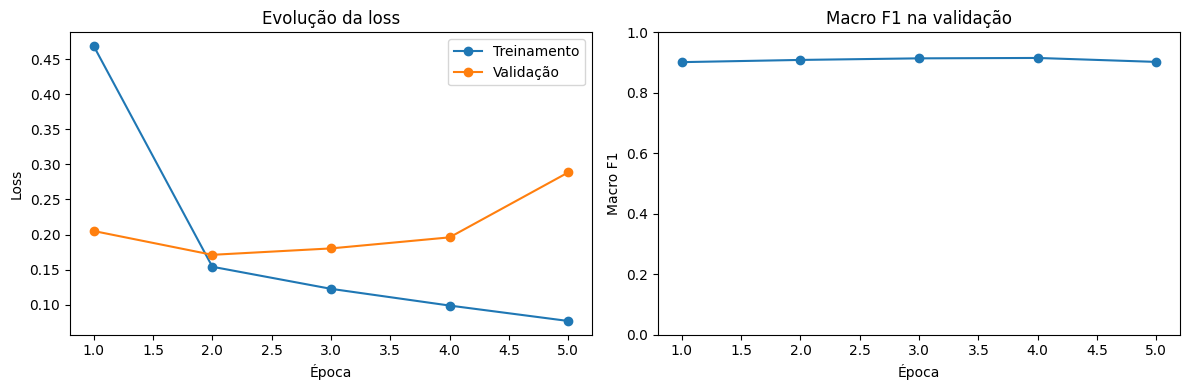

              precision    recall  f1-score   support

     sadness     0.9422    0.9782    0.9599       550
         joy     0.9641    0.9545    0.9593       704
        love     0.8920    0.8820    0.8870       178
       anger     0.9879    0.8873    0.9349       275
        fear     0.8603    0.9292    0.8934       212
    surprise     0.8625    0.8519    0.8571        81

    accuracy                         0.9385      2000
   macro avg     0.9182    0.9139    0.9153      2000
weighted avg     0.9398    0.9385    0.9385      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,validation,0.195999,0.9385,0.918167,0.913853,0.915268,0.939822,0.9385,0.938544


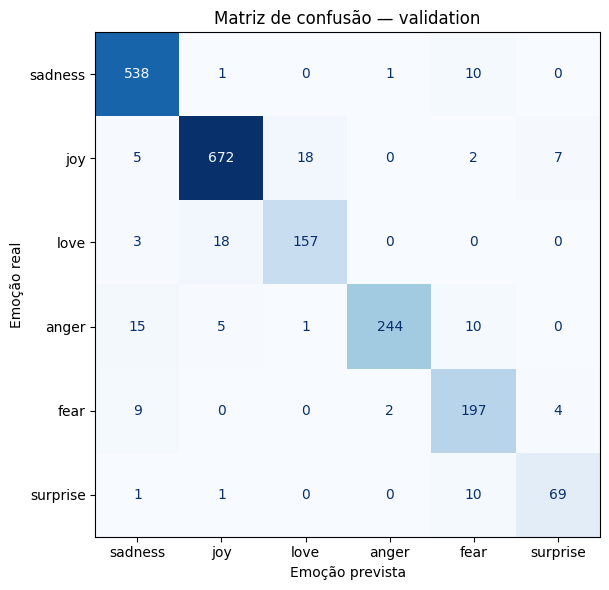

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [46]:
resultado_baseline = treinar_experimento("baseline", HIPERPARAMETROS_FIXOS)


## Referência com encoder congelado

Nesta configuração, as representações do DistilBERT pré-treinado são utilizadas **sem atualizar embeddings ou encoder Transformer**. Somente a cabeça de classificação, incluindo `pre_classifier` e `classifier`, é treinada. Dropout não possui parâmetros.

Usamos até cinco épocas com os mesmos hiperparâmetros fixos do baseline e selecionamos o melhor checkpoint pela validação. Os artefatos ficam em `results/frozen/`. A célula abaixo executa o treinamento da cabeça e salva o melhor checkpoint.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


frozen {'totais': 66958086, 'treinaveis': 595206}


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.525993,1.443345,0.498500,0.202787
2,1.400311,1.355494,0.506000,0.207144
3,1.338488,1.310699,0.512500,0.215559
4,1.301284,1.290004,0.522000,0.246827
5,1.272502,1.250977,0.546000,0.297550


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,1.525993,1.443345,0.4985,0.202787
1,2.0,1.400311,1.355494,0.5060,0.207144
2,3.0,1.338488,1.310699,0.5125,0.215559
3,4.0,1.301284,1.290004,0.5220,0.246827
4,5.0,1.272502,1.250977,0.5460,0.297550


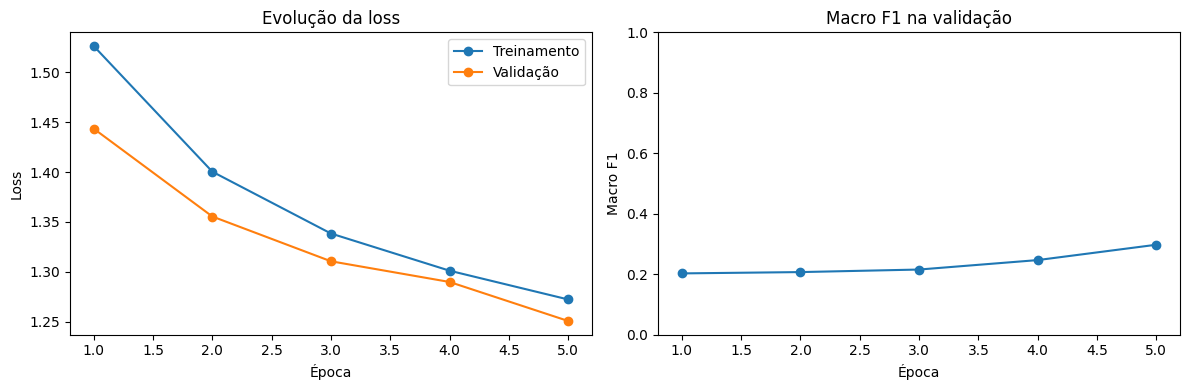

              precision    recall  f1-score   support

     sadness     0.4789    0.8236    0.6056       550
         joy     0.6218    0.8011    0.7002       704
        love     1.0000    0.0112    0.0222       178
       anger     0.5500    0.1600    0.2479       275
        fear     0.4462    0.1368    0.2094       212
    surprise     0.0000    0.0000    0.0000        81

    accuracy                         0.5460      2000
   macro avg     0.5161    0.3221    0.2975      2000
weighted avg     0.5625    0.5460    0.4713      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,validation,1.250977,0.546,0.51614,0.322134,0.29755,0.562488,0.546,0.471267


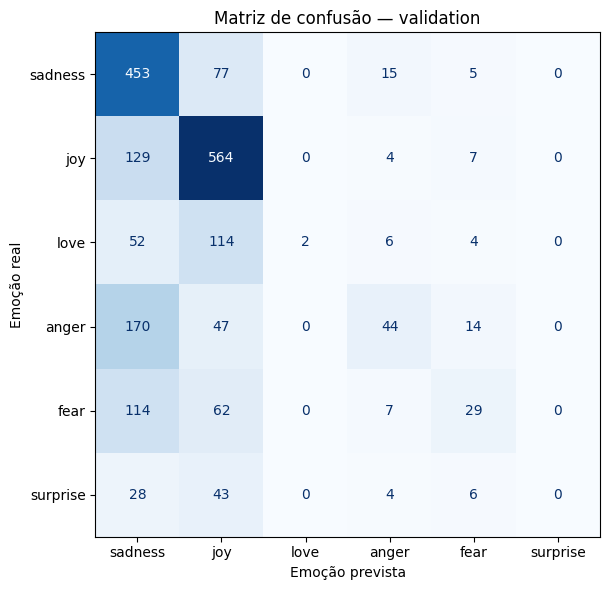

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [47]:
resultado_frozen = treinar_experimento(
    "frozen", HIPERPARAMETROS_FIXOS, congelado=True,
)


## Otimização com Optuna

O estudo maximiza o **melhor Macro F1 de validação** de cada trial. O espaço de busca inclui learning rate logarítmico entre 1e-5 e 5e-5, batch size 16 ou 32, weight decay entre 0 e 0.1 e warmup ratio entre 0 e 0.1. O limite é de cinco épocas.

Usamos scheduler `constant_with_warmup`: o learning rate cresce durante o warmup e depois permanece constante. O número de passos de warmup é calculado a partir do ratio e do tamanho do treinamento.

O sampler TPE usa seed 42. O MedianPruner aguarda **cinco trials completos** e **três épocas** antes de permitir poda. O early stopping monitora Macro F1 com paciência de duas avaliações. O pruning reporta o melhor F1 acumulado, coerente com o objetivo e com a seleção do checkpoint.

O estudo fica em SQLite em `results/optuna/estudo.sqlite3`. Trials concluídos são reutilizados; a retomada completa um orçamento total de **15 tentativas finalizadas** (COMPLETE, PRUNED ou FAIL), sem executar outras 15 a cada chamada. Pesos originais são carregados em cada trial; nenhum modelo de trial é mantido após a avaliação.

A seed não garante a mesma sequência de sugestões depois de reiniciar o processo, pois o SQLite guarda trials, mas não o estado aleatório interno do sampler. No Colab, preserve a pasta `results/optuna/` entre sessões; não execute buscas concorrentes neste SQLite.

Referências: [MedianPruner](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.pruners.MedianPruner.html), [persistência do estudo](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html).

Ao encerrar a busca, o notebook imprime o melhor trial e seus hiperparâmetros, o melhor Macro F1 de validação e a tabela de todas as tentativas. COMPLETE, PRUNED e FAIL contam no orçamento total de 15; trials já finalizados no SQLite não são repetidos.

O histórico e a duração das tentativas são salvos como gráfico. A importância dos hiperparâmetros usa fANOVA com seed 42 e somente trials COMPLETE, exigindo pelo menos cinco, variação de parâmetros e do F1. Essa importância é uma estimativa exploratória; parâmetros que não variaram não recebem importância calculada. Referência: [importância dos hiperparâmetros](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.importance.get_param_importances.html).


In [48]:
PASTA_OPTUNA = RAIZ_RESULTADOS / "optuna"
PASTA_OPTUNA.mkdir(exist_ok=True)
TOTAL_TRIALS = 15

estudo = optuna.create_study(
    study_name="distilbert_emotion_5epocas_v1",
    storage="sqlite:///" + (PASTA_OPTUNA / "estudo.sqlite3").resolve().as_posix(),
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMENTE),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=3, interval_steps=1, n_min_trials=3,
    ),
    load_if_exists=True,
)


class RelatarTrialCallback(TrainerCallback):
    def __init__(self, trial, pasta):
        self.trial = trial
        self.pasta = pasta
        self.melhor_f1 = -1.0

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        epoca = int(round(state.epoch))
        f1 = float(metrics["eval_f1_macro"])
        if f1 > self.melhor_f1:
            self.melhor_f1 = f1
            self.trial.set_user_attr("epoca_selecionada", epoca)
        self.trial.report(self.melhor_f1, step=epoca)
        self.trial.set_user_attr("melhor_f1_validacao", self.melhor_f1)
        # Salva por época para preservar progresso mesmo em uma interrupção.
        salvar_historico(list(state.log_history), self.pasta, graficos=False)
        if self.trial.should_prune():
            raise optuna.TrialPruned(f"Trial podado após a época {epoca}")


def objetivo_optuna(trial):
    hp = {
        **HIPERPARAMETROS_FIXOS,
        "learning_rate": trial.suggest_float("learning_rate", 1e-5, 5e-5, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.1),
        "scheduler": "constant_with_warmup",
        "epocas": 5,
    }
    resultado = treinar_experimento(
        "optuna_trial", hp, trial=trial, early_stopping=True,
    )
    return resultado["f1_macro"]


def exportar_trials():
    linhas = []
    for trial in estudo.trials:
        linhas.append({
            "trial": trial.number, "estado": trial.state.name,
            "f1_macro": trial.value,
            "duracao_segundos": (
                trial.duration.total_seconds() if trial.duration is not None else None
            ),
            **trial.params,
            "epoca_selecionada": trial.user_attrs.get("epoca_selecionada"),
        })
    colunas = [
        "trial", "estado", "f1_macro", "duracao_segundos",
        "learning_rate", "batch_size", "weight_decay", "warmup_ratio",
        "epoca_selecionada",
    ]
    tabela = pd.DataFrame(linhas, columns=colunas)
    tabela.to_csv(PASTA_OPTUNA / "trials.csv", index=False)
    salvar_json(PASTA_OPTUNA / "trials.json", linhas)
    return tabela


def apresentar_resultados_optuna():
    tabela = exportar_trials()
    with pd.option_context("display.max_columns", None):
        display(tabela)
    finalizados = sum(t.state.is_finished() for t in estudo.trials)
    print(f"Tentativas finalizadas: {finalizados}/{TOTAL_TRIALS}")
    completos = estudo.get_trials(states=(TrialState.COMPLETE,))
    if not completos:
        print("Nenhum trial COMPLETE disponível para selecionar o melhor ou gerar os gráficos.")
        return tabela

    melhor = estudo.best_trial
    resumo = {
        "trial": melhor.number,
        "estado": melhor.state.name,
        "metrica": "Macro F1 na validação",
        "f1_macro_validacao": float(melhor.value),
        "hiperparametros": melhor.params,
        "epoca_selecionada": melhor.user_attrs.get("epoca_selecionada"),
    }
    # Este resumo não indica que o treinamento final otimizado já foi realizado.
    salvar_json(PASTA_OPTUNA / "resumo_melhor_trial.json", resumo)
    print("Melhor trial:", melhor.number)
    print(f"Melhor Macro F1 de validação: {melhor.value:.6f}")
    display(pd.DataFrame(melhor.params.items(), columns=["Hiperparâmetro", "Valor"]))

    concluidos = tabela.loc[tabela["estado"] == "COMPLETE"].sort_values("trial")
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    eixos[0].plot(concluidos["trial"], concluidos["f1_macro"], "o", label="Trial completo")
    eixos[0].plot(
        concluidos["trial"], concluidos["f1_macro"].cummax(),
        label="Melhor acumulado",
    )
    eixos[0].set(
        title="Histórico da otimização", xlabel="Trial",
        ylabel="Macro F1 de validação",
    )
    eixos[0].legend()
    eixos[1].bar(tabela["trial"], tabela["duracao_segundos"].fillna(0))
    eixos[1].set(title="Duração das tentativas", xlabel="Trial", ylabel="Segundos")
    fig.tight_layout()
    fig.savefig(PASTA_OPTUNA / "evolucao_trials.png", dpi=150)
    plt.show()
    plt.close(fig)

    # A importância precisa de trials completos e variação dos parâmetros e do F1.
    parametros = [
        nome for nome in ("learning_rate", "batch_size", "weight_decay", "warmup_ratio")
        if all(nome in t.params for t in completos)
        and len({t.params[nome] for t in completos}) > 1
    ]
    if len(completos) < 5 or not parametros or len({t.value for t in completos}) < 2:
        print("Importância: aguarde pelo menos 5 trials COMPLETE com parâmetros e F1 variados.")
        return tabela
    try:
        importancias = optuna.importance.get_param_importances(
            estudo,
            evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEMENTE),
            params=parametros,
        )
    except (ValueError, RuntimeError) as erro:
        print("Ainda não foi possível estimar a importância:", erro)
        return tabela

    salvar_json(PASTA_OPTUNA / "importancia_hiperparametros.json", importancias)
    tabela_importancias = pd.DataFrame(
        importancias.items(), columns=["Hiperparâmetro", "Importância"],
    )
    tabela_importancias.to_csv(PASTA_OPTUNA / "importancia_hiperparametros.csv", index=False)
    display(tabela_importancias)
    ax = tabela_importancias.sort_values("Importância").plot.barh(
        x="Hiperparâmetro", y="Importância", legend=False, figsize=(8, 4),
    )
    ax.set(title="Importância dos hiperparâmetros — fANOVA", xlabel="Importância relativa")
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(PASTA_OPTUNA / "importancia_hiperparametros.png", dpi=150)
    plt.show()
    plt.close(fig)
    return tabela


def executar_busca_optuna():
    # RUNNING após queda do processo não é retomado por dentro do treinamento.
    # Exige intervenção explícita, evitando alterar um trial ainda em execução.
    pendentes = [t.number for t in estudo.trials if t.state == TrialState.RUNNING]
    if pendentes:
        raise RuntimeError(
            f"Trials RUNNING: {pendentes}. Se o processo anterior terminou, "
            "marque-os como FAIL com estudo.tell(numero, state=TrialState.FAIL)."
        )
    terminados = sum(t.state.is_finished() for t in estudo.trials)
    restantes = max(0, TOTAL_TRIALS - terminados)
    try:
        if restantes:
            estudo.optimize(
                objetivo_optuna, n_trials=restantes, n_jobs=1, gc_after_trial=True,
                catch=(torch.OutOfMemoryError,),
                callbacks=[lambda estudo_atual, trial: exportar_trials()],
            )
    finally:
        # Inclui estados e duração mesmo se a busca for interrompida.
        apresentar_resultados_optuna()


[I 2026-11-16 14:44:22,882] Using an existing study with name 'distilbert_emotion_5epocas_v1' instead of creating a new one.


### Execução da busca

A célula abaixo executa a otimização com orçamento total de **15 trials** e até cinco épocas por trial. O SQLite permite retomar a busca sem repetir tentativas finalizadas.

Ao terminar (ou interromper), a função exibe e exporta os resultados disponíveis em `results/optuna/`: `trials.csv`, `trials.json`, `resumo_melhor_trial.json`, `evolucao_trials.png` e, quando possível, `importancia_hiperparametros.csv/json/png`.

Para reapresentar os resultados sem treinar, execute `apresentar_resultados_optuna()`.


In [49]:
executar_busca_optuna()


Otimização com Optuna concluída.
Trials finalizados: 15 (8 completos e 7 podados).
Melhor trial: 0
Melhor Macro F1 de validação: 0.920638
Resultados detalhados: results/optuna/
Modelo final e tokenizer salvos em: results/optuna/melhor_modelo/


## Seleção e treinamento final com os melhores hiperparâmetros

Após encerrar o orçamento da busca, recuperamos o melhor trial **COMPLETE**, seus hiperparâmetros e a época selecionada. O modelo final parte novamente dos pesos originais e repete o protocolo de até cinco épocas, early stopping com paciência dois e seleção do maior Macro F1 na validação.

A época do trial fica registrada para auditoria; não concatenamos treino e validação nem escolhemos épocas pelo teste. O melhor checkpoint do novo treinamento será salvo em `results/optuna/melhor_modelo/`. A célula abaixo verifica a conclusão da busca e executa o treinamento final com os hiperparâmetros selecionados.


,trial,f1_macro_validacao,epoca_selecionada_trial,hiperparametros
0,0,0.920638,4.0,"{'modelo': 'distilbert-base-uncased', 'learnin..."


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


optuna {'totais': 66958086, 'treinaveis': 66958086}


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.534432,0.204366,0.924500,0.896698
2,0.161730,0.166075,0.941000,0.916367
3,0.121562,0.164476,0.940500,0.914863
4,0.097429,0.202177,0.941000,0.920638
5,0.077324,0.242427,0.937000,0.909699


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.534432,0.204366,0.9245,0.896698
1,2.0,0.161730,0.166075,0.9410,0.916367
2,3.0,0.121562,0.164476,0.9405,0.914863
3,4.0,0.097429,0.202177,0.9410,0.920638
4,5.0,0.077324,0.242427,0.9370,0.909699


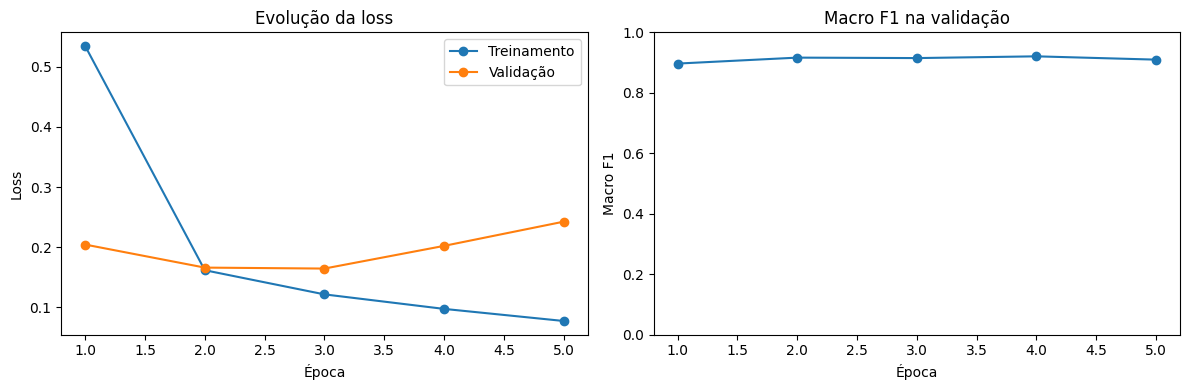

              precision    recall  f1-score   support

     sadness     0.9487    0.9745    0.9614       550
         joy     0.9835    0.9332    0.9577       704
        love     0.8711    0.9494    0.9086       178
       anger     0.9802    0.9018    0.9394       275
        fear     0.8487    0.9528    0.8978       212
    surprise     0.8537    0.8642    0.8589        81

    accuracy                         0.9410      2000
   macro avg     0.9143    0.9293    0.9206      2000
weighted avg     0.9439    0.9410    0.9415      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,validation,0.202177,0.941,0.914329,0.929345,0.920638,0.943942,0.941,0.941496


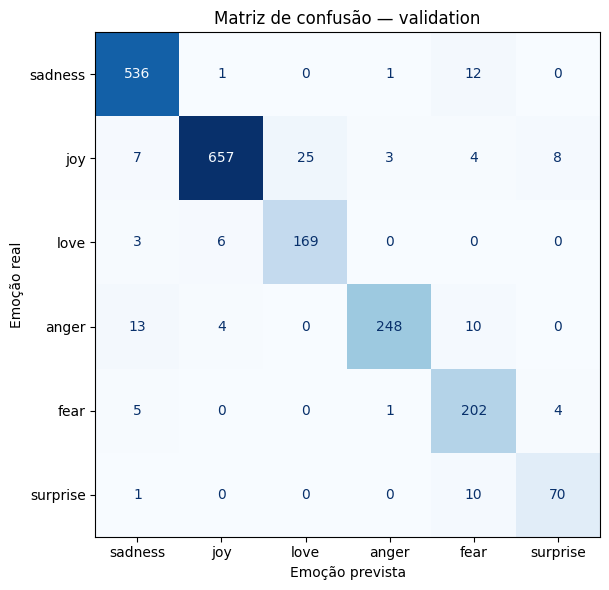

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [50]:
if any(t.state == TrialState.RUNNING for t in estudo.trials):
    raise RuntimeError("Ainda existe um trial em execução.")
if sum(t.state.is_finished() for t in estudo.trials) < TOTAL_TRIALS:
    raise RuntimeError(f"Conclua o orçamento de {TOTAL_TRIALS} trials antes do treinamento final.")
completos = estudo.get_trials(states=(TrialState.COMPLETE,))
if not completos:
    raise RuntimeError("Nenhum trial concluído com sucesso.")
melhor_trial = estudo.best_trial
hp_otimizados = {
    **HIPERPARAMETROS_FIXOS, **melhor_trial.params,
    "scheduler": "constant_with_warmup",
}
selecao_optuna = {
    "trial": melhor_trial.number, "f1_macro_validacao": melhor_trial.value,
    "epoca_selecionada_trial": melhor_trial.user_attrs["epoca_selecionada"],
    "hiperparametros": hp_otimizados,
}
display(pd.DataFrame([selecao_optuna]))
resultado_otimizado = treinar_experimento(
    "optuna", hp_otimizados, early_stopping=True,
)
salvar_json(PASTA_OPTUNA / "melhor_trial.json", selecao_optuna)


## Comparação dos três modelos na validação e evolução dos trials

A tabela identifica explicitamente **validação** e apresenta todas as métricas e o tempo de treinamento. Somente experimentos concluídos no protocolo de cinco épocas são incluídos; resultados antigos ou ainda ausentes não são preenchidos.

Os gráficos comparam as métricas macro/weighted e mostram o Macro F1 dos trials concluídos, o melhor valor acumulado e a duração de cada tentativa. Ainda não há seleção pelo teste.


,Modelo,Divisão,accuracy,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,Tempo de treinamento (s)
0,Encoder congelado,validation,0.5460,0.516140,0.562488,0.322134,0.5460,0.297550,0.471267,114.048504
1,Baseline (5 épocas),validation,0.9385,0.918167,0.939822,0.913853,0.9385,0.915268,0.938544,350.831180
2,Otimizado por Optuna,validation,0.9410,0.914329,0.943942,0.929345,0.9410,0.920638,0.941496,315.561751


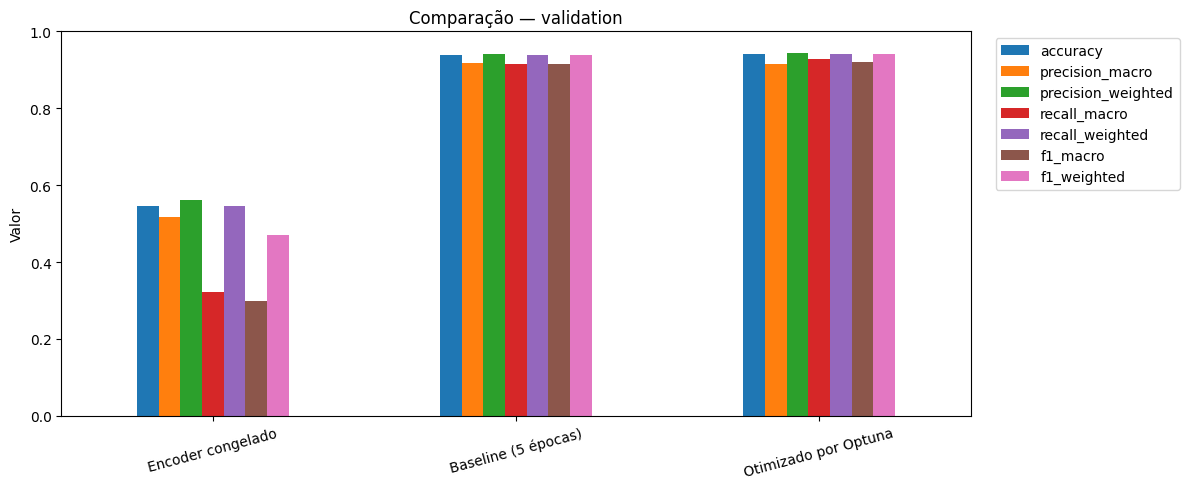

,trial,estado,f1_macro,duracao_segundos,learning_rate,batch_size,weight_decay,warmup_ratio,epoca_selecionada
0,0,COMPLETE,0.920638,367.899891,0.000018,16,0.059866,0.015602,4.0
1,1,COMPLETE,0.914666,289.025259,0.000013,32,0.060112,0.070807,3.0
2,2,COMPLETE,0.915029,357.738359,0.000010,16,0.021234,0.018182,4.0
3,3,COMPLETE,0.915113,289.065495,0.000013,32,0.043195,0.029123,3.0
4,4,COMPLETE,0.918656,282.519418,0.000027,32,0.036636,0.045607,4.0
5,5,PRUNED,0.913309,168.783815,0.000035,32,0.059241,0.004645,3.0
6,6,COMPLETE,0.917247,368.850416,0.000027,16,0.094889,0.096563,4.0
7,7,PRUNED,0.906607,211.671047,0.000037,16,0.068423,0.044015,2.0
8,8,PRUNED,0.913036,208.115990,0.000012,16,0.090932,0.025878,3.0
9,9,PRUNED,0.914143,156.687729,0.000029,32,0.054671,0.018485,3.0


Tentativas finalizadas: 15/15
Melhor trial: 0
Melhor Macro F1 de validação: 0.920638


,Hiperparâmetro,Valor
0,learning_rate,0.000018
1,batch_size,16.000000
2,weight_decay,0.059866
3,warmup_ratio,0.015602


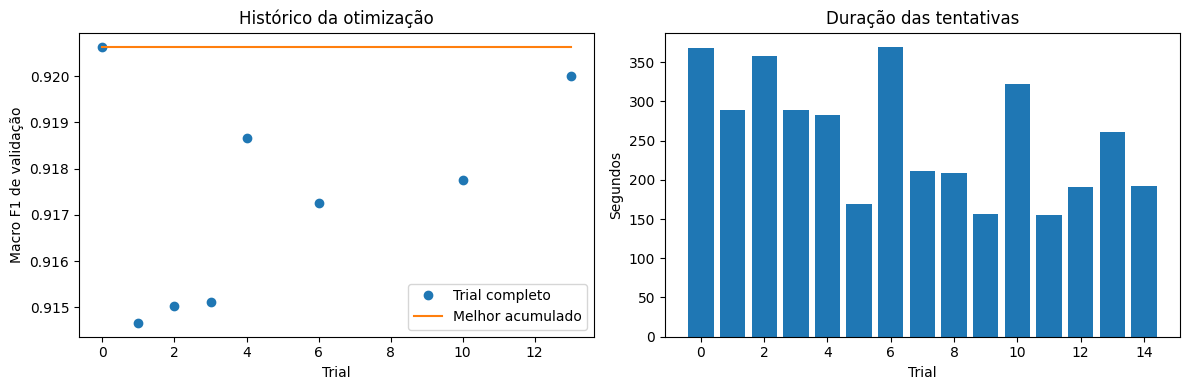

,Hiperparâmetro,Importância
0,learning_rate,0.668093
1,warmup_ratio,0.196102
2,weight_decay,0.093478
3,batch_size,0.042327


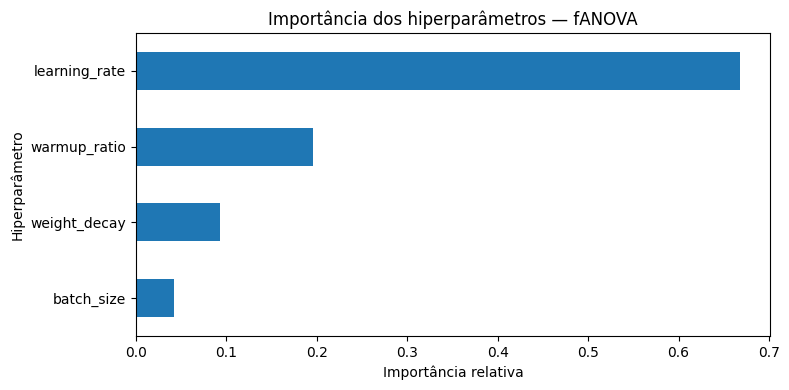

In [51]:
CONFIGURACOES = {
    "Encoder congelado": "frozen",
    "Baseline (5 épocas)": "baseline",
    "Otimizado por Optuna": "optuna",
}
COLUNAS_METRICAS = [
    "accuracy", "precision_macro", "precision_weighted", "recall_macro",
    "recall_weighted", "f1_macro", "f1_weighted",
]


def tabela_comparativa(divisao="validation"):
    linhas = []
    for nome, pasta in CONFIGURACOES.items():
        raiz = RAIZ_RESULTADOS / pasta
        arquivo_hp = raiz / "hiperparametros.json"
        if not arquivo_hp.exists():
            print("Ainda não executado:", nome)
            continue
        hp = json.loads(arquivo_hp.read_text(encoding="utf-8"))
        if hp.get("epocas") != 5:
            print("Protocolo anterior, excluído da comparação:", nome)
            continue
        arquivo_estado = raiz / "estado_execucao.json"
        if not arquivo_estado.exists():
            continue
        estado = json.loads(arquivo_estado.read_text(encoding="utf-8"))
        if estado["estado"] != "COMPLETE":
            continue
        pasta_metricas = raiz if divisao == "validation" else raiz / "teste"
        arquivo = pasta_metricas / ("metricas_validacao.json" if divisao == "validation" else "metricas_teste.json")
        if not arquivo.exists():
            continue
        metricas = json.loads(arquivo.read_text(encoding="utf-8"))
        tempo = json.loads((raiz / "tempo_treinamento.json").read_text(encoding="utf-8"))
        linhas.append({
            "Modelo": nome, "Divisão": divisao,
            **{chave: metricas[chave] for chave in COLUNAS_METRICAS},
            "Tempo de treinamento (s)": tempo["segundos"],
        })
    tabela = pd.DataFrame(linhas)
    if not tabela.empty:
        tabela.to_csv(RAIZ_RESULTADOS / f"comparacao_{divisao}.csv", index=False)
        display(tabela)
        ax = tabela.set_index("Modelo")[COLUNAS_METRICAS].plot.bar(
            figsize=(12, 5), ylim=(0, 1), rot=15,
        )
        ax.set(title=f"Comparação — {divisao}", ylabel="Valor", xlabel="")
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
        fig = ax.get_figure()
        fig.tight_layout()
        fig.savefig(RAIZ_RESULTADOS / f"comparacao_{divisao}.png", dpi=150)
        plt.show()
        plt.close(fig)
    return tabela


comparacao_validacao = tabela_comparativa("validation")
tabela_trials = apresentar_resultados_optuna()


## Avaliação final no conjunto de teste

Esta seção executa **depois da busca, do treinamento final e da comparação de validação**. Ela verifica os artefatos de seleção e carrega os três modelos salvos, sem treinar ou escolher novos checkpoints.

Os três modelos são avaliados na mesma divisão original de teste. Os resultados ficam em `results/<configuracao>/teste/`, e a comparação é identificada como `test`. Os resultados do teste não influenciam a busca, os hiperparâmetros ou a seleção dos checkpoints.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

              precision    recall  f1-score   support

     sadness     0.4777    0.7728    0.5904       581
         joy     0.5998    0.8043    0.6872       695
        love     0.0000    0.0000    0.0000       159
       anger     0.6056    0.1564    0.2486       275
        fear     0.4912    0.1250    0.1993       224
    surprise     0.0000    0.0000    0.0000        66

    accuracy                         0.5395      2000
   macro avg     0.3624    0.3097    0.2876      2000
weighted avg     0.4855    0.5395    0.4668      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,test,1.224089,0.5395,0.362384,0.309748,0.287566,0.485478,0.5395,0.466794


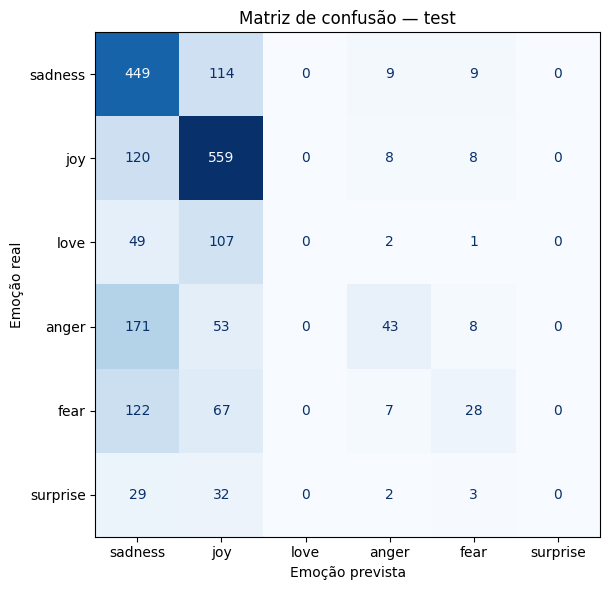

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

              precision    recall  f1-score   support

     sadness     0.9498    0.9776    0.9635       581
         joy     0.9561    0.9410    0.9485       695
        love     0.8182    0.8491    0.8333       159
       anger     0.9755    0.8691    0.9192       275
        fear     0.8410    0.8973    0.8683       224
    surprise     0.7101    0.7424    0.7259        66

    accuracy                         0.9230      2000
   macro avg     0.8751    0.8794    0.8765      2000
weighted avg     0.9250    0.9230    0.9234      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,test,0.218302,0.923,0.875136,0.879421,0.876464,0.924991,0.923,0.923357


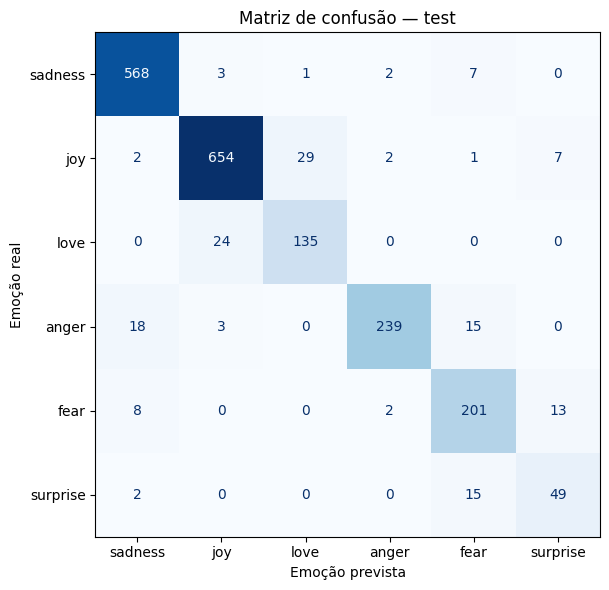

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

              precision    recall  f1-score   support

     sadness     0.9512    0.9725    0.9617       581
         joy     0.9713    0.9252    0.9477       695
        love     0.7857    0.8994    0.8387       159
       anger     0.9563    0.8764    0.9146       275
        fear     0.8353    0.9286    0.8795       224
    surprise     0.7541    0.6970    0.7244        66

    accuracy                         0.9230      2000
   macro avg     0.8757    0.8832    0.8778      2000
weighted avg     0.9262    0.9230    0.9235      2000



,divisao,loss,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,test,0.237019,0.923,0.875663,0.883153,0.877767,0.92625,0.923,0.923538


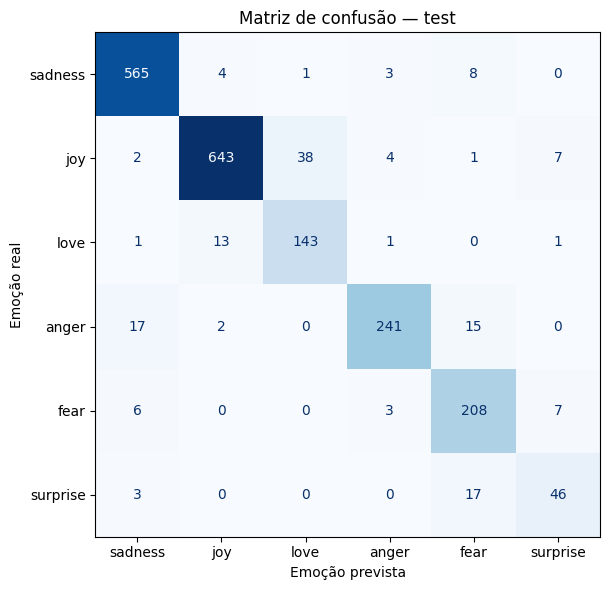

,Modelo,Divisão,accuracy,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,Tempo de treinamento (s)
0,Encoder congelado,test,0.5395,0.362384,0.485478,0.309748,0.5395,0.287566,0.466794,114.048504
1,Baseline (5 épocas),test,0.9230,0.875136,0.924991,0.879421,0.9230,0.876464,0.923357,350.831180
2,Otimizado por Optuna,test,0.9230,0.875663,0.926250,0.883153,0.9230,0.877767,0.923538,315.561751


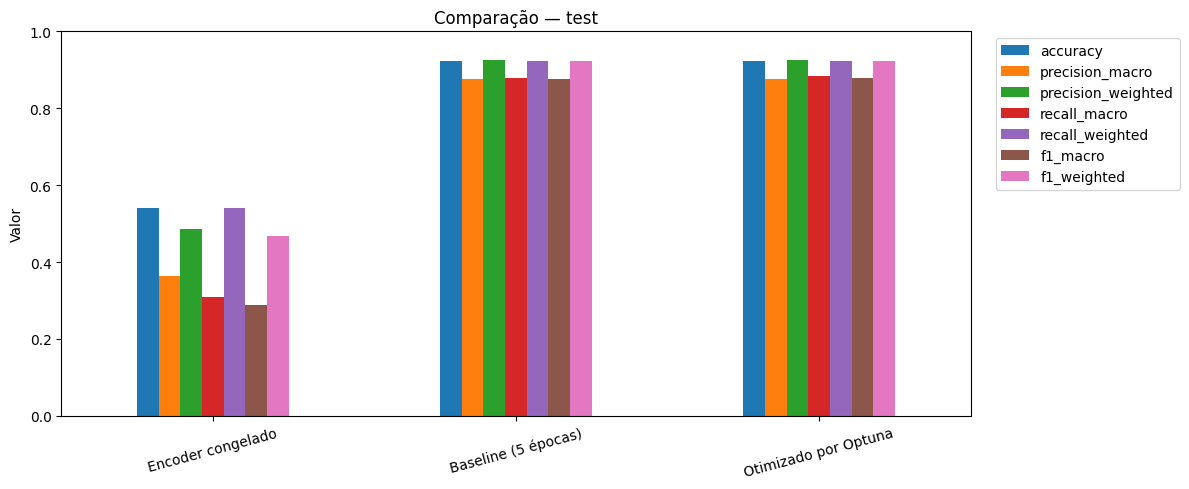

In [52]:
caminhos_modelos = {}
for nome, pasta in CONFIGURACOES.items():
    raiz = RAIZ_RESULTADOS / pasta
    for arquivo in ("hiperparametros.json", "estado_execucao.json",
                    "selecao_melhor_modelo.json", "melhor_modelo/config.json"):
        if not (raiz / arquivo).exists():
            raise RuntimeError(f"Finalize e preserve {nome} antes de acessar o teste.")
    hp = json.loads((raiz / "hiperparametros.json").read_text(encoding="utf-8"))
    estado = json.loads((raiz / "estado_execucao.json").read_text(encoding="utf-8"))
    if hp["epocas"] != 5 or estado["estado"] != "COMPLETE":
        raise RuntimeError(f"Protocolo incompleto: {nome}")
    caminhos_modelos[nome] = (raiz, hp)
if not (PASTA_OPTUNA / "melhor_trial.json").exists():
    raise RuntimeError("A seleção definitiva do Optuna ainda não foi salva.")

for nome, (raiz, hp) in caminhos_modelos.items():
    modelo_teste = None
    trainer_teste = None
    try:
        modelo_teste = AutoModelForSequenceClassification.from_pretrained(
            raiz / "melhor_modelo",
        )
        with tempfile.TemporaryDirectory(prefix="avaliacao_") as temporaria:
            trainer_teste = criar_trainer(modelo_teste, hp, temporaria)
            avaliar_e_salvar(trainer_teste, "test", raiz / "teste")
    finally:
        if trainer_teste is not None:
            trainer_teste.accelerator.free_memory()
        trainer_teste = None
        modelo_teste = None
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
comparacao_teste = tabela_comparativa("test")


## Execução completa e preservação dos arquivos

No Google Colab, selecione um ambiente com **GPU** e use **Ambiente de execução → Executar tudo**. As células executam em ordem: preparação dos dados, baseline de cinco épocas, encoder congelado, Optuna com 15 trials, treinamento do modelo otimizado, comparação na validação e avaliação final no teste.

Não há chaves de ativação para os treinamentos ou para o teste. As verificações de conclusão da busca e da presença dos modelos permanecem para garantir a ordem do experimento. O teste é acessado somente após a seleção dos três modelos.

Ao repetir o notebook, os experimentos anteriores são preservados antes de uma nova gravação. O Optuna utiliza o SQLite para completar apenas o orçamento restante de 15 tentativas.

No Colab, faça backup de `results/` antes de encerrar a sessão; copiar somente o notebook não preserva modelos nem SQLite. Os pesos dos modelos ficam fora do Git. O tempo da busca é registrado por trial e não deve ser confundido com o tempo de um único treinamento final.
